# 부산도서관 장서 대출 데이터 분석 (2026년 9월 기준)

**데이터**: `부산도서관 장서 대출목록 (2026년 09월).csv` — 부산도서관이 소장한 장서 1권(등록 단위)당 1행, 약 66만 행

**분석 질문**
1. 장서는 얼마나 고르게 이용되고 있는가? (대출 집중도, 미대출 장서)
2. 어떤 주제·이용대상의 책이 장서 규모에 비해 많이/적게 빌려지는가? (수요-공급 불균형)
3. 언제 들어온 책, 언제 나온 책이 잘 빌려지는가? (등록 시기·출간 연도 효과)
4. 어떤 책·작가·출판사가 인기 있는가?
5. 복본(같은 책 여러 권)은 효과가 있는가?
6. 장서 개발·관리에 어떤 시사점이 있는가?

**목차**
0. 준비 및 데이터 개요
1. 전처리
2. 대출 분포와 집중도
3. 주제분류(KDC)별 분석
4. 이용대상(부가기호)별 분석
5. 등록 시기(코호트) 분석
6. 출간 연도 분석
7. 인기 도서·저자·출판사
8. 복본 분석
9. 미대출 장서 분석
10. 종합 인사이트 및 제언

> ⚠️ **해석상 주의**: `대출건수`는 2026년 9월 한 달의 대출이 아니라 **등록 이후 누적 대출건수**로 판단됩니다
> (최댓값 170회, 2020년 등록 도서일수록 값이 큼). 따라서 오래 보유한 책일수록 유리하므로,
> 공정한 비교가 필요한 곳에서는 **월평균 대출(=누적 대출 ÷ 보유 개월)** 을 함께 사용합니다.

## 0. 준비 및 데이터 개요

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.2f}'.format)

# 한글 폰트 (macOS: AppleGothic, Windows: Malgun Gothic, Linux: NanumGothic)
import matplotlib.font_manager as fm
_fonts = {f.name for f in fm.fontManager.ttflist}
for _f in ['AppleGothic', 'Apple SD Gothic Neo', 'Malgun Gothic', 'NanumGothic', 'Nanum Gothic']:
    if _f in _fonts:
        plt.rcParams['font.family'] = _f
        break
plt.rcParams.update({
    'axes.unicode_minus': False,
    'figure.dpi': 110,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'text.color': '#0b0b0b',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

# 색상: 기본은 파랑 한 가지, 비교 대상은 주황, 강조 안 하는 항목은 회색
BLUE, ORANGE, GRAY, RED = '#2a78d6', '#eb6834', '#b9b8b1', '#e34948'
INK2 = '#52514e'
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f3f8fe', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])

DATA_PATH = '/Users/honghyeon-a/Downloads/부산도서관 장서 대출목록 (2026년 09월).csv'
REF_DATE = pd.Timestamp('2026-09-30')   # 기준일: 2026년 9월 말

In [2]:
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig', dtype=str)
print('원본 크기:', raw.shape)
raw.head()

원본 크기: (659791, 14)


,번호,도서명,저자,출판사,발행년도,ISBN,세트 ISBN,부가기호,권,주제분류번호,도서권수,대출건수,등록일자,Unnamed: 13
0,1,세이프 타운,장세아 지음,NaN,2026,9791170613756,NaN,0,NaN,813.7,1,0,2026-08-04,NaN
1,2,퀸에이저,엘리너 밀스 지음;방진이 옮김,교보문고(단행본),2026,9791170613909,NaN,0,NaN,331.235,1,0,2026-08-04,NaN
2,3,우리가 미처 몰랐던 고려,박종기 지음,휴머니스트,2026,9791170875208,NaN,0,NaN,911.04,1,0,2026-08-04,NaN
3,4,오늘내일하는 사이,임봉근;임다운 [공]지음,안온북스,2026,9791192638850,NaN,0,NaN,814.7,1,0,2026-08-04,NaN
4,5,오늘도 강박과 살아갑니다,신재현 지음,시그마북스,2026,9791168624832,NaN,0,NaN,513.8522,1,0,2026-08-04,NaN


In [3]:
# 컬럼별 결측률 / 고유값 수
overview = pd.DataFrame({
    '결측률(%)': raw.isna().mean() * 100,
    '고유값 수': raw.nunique(),
    '예시': raw.iloc[0],
})
overview

,결측률(%),고유값 수,예시
번호,0.00,659791,1
도서명,0.01,440967,세이프 타운
저자,0.05,333189,장세아 지음
출판사,3.22,26108,NaN
발행년도,0.11,2272,2026
ISBN,0.00,460802,9791170613756
세트 ISBN,94.75,7052,NaN
부가기호,32.96,20,0
권,89.16,2036,NaN
주제분류번호,12.79,13616,813.7


**관찰**
- 마지막 컬럼 `Unnamed: 13`은 각 행 끝의 쉼표 때문에 생긴 빈 컬럼 → 제거
- `세트 ISBN`(95% 결측), `권`(89% 결측)은 시리즈/세트 도서에만 값이 있음
- `주제분류번호`는 약 13% 결측 → '미분류'로 따로 둠
- `부가기호` 첫 자리 = 독자대상 기호(0 교양, 1 실용, 4 청소년, 7 아동, 9 전문 등), 33% 결측
- `도서권수`는 거의 모두 1 → **한 행 = 한 권(등록번호)**. 같은 책을 여러 권 가진 경우는 ISBN이 같은 여러 행으로 나타남

## 1. 전처리

In [4]:
df = raw.loc[:, ~raw.columns.str.startswith('Unnamed')].copy()

# 숫자/날짜 변환
df['대출건수'] = pd.to_numeric(df['대출건수'], errors='coerce').fillna(0).astype(int)
df['도서권수'] = pd.to_numeric(df['도서권수'], errors='coerce').fillna(1).astype(int)
df['발행년도'] = pd.to_numeric(df['발행년도'].str.extract(r'(\d{4})')[0], errors='coerce')
df.loc[(df['발행년도'] < 1900) | (df['발행년도'] > 2026), '발행년도'] = np.nan
df['등록일자'] = pd.to_datetime(df['등록일자'], errors='coerce')

# KDC 대분류 / 중분류
KDC = {'0': '총류', '1': '철학', '2': '종교', '3': '사회과학', '4': '자연과학',
       '5': '기술과학', '6': '예술', '7': '언어', '8': '문학', '9': '역사'}
kdc_digit = df['주제분류번호'].str.extract(r'^\s*(\d)')[0]
df['주제'] = kdc_digit.map(KDC).fillna('미분류')
df['KDC중분류'] = df['주제분류번호'].str.extract(r'^\s*(\d{2})')[0]

# 독자대상 (부가기호 첫 자리)
READER = {'0': '교양', '1': '실용', '2': '여성', '4': '청소년', '5': '학습참고(중고)',
          '6': '학습참고(초등)', '7': '아동', '9': '전문'}
df['이용대상'] = df['부가기호'].str.strip().str[:1].map(READER).fillna('미상')

# 보유기간 & 월평균 대출 (누적 대출건수 보정)
df['등록연도'] = df['등록일자'].dt.year
df['보유개월'] = ((REF_DATE - df['등록일자']).dt.days / 30.44).clip(lower=0.5)
df['월평균대출'] = df['대출건수'] / df['보유개월']
df['미대출'] = df['대출건수'] == 0
df['출간후등록(년)'] = df['등록연도'] - df['발행년도']

# 저자 정리: 첫 번째 저자만, 역할어(지음/글/그림/옮김 등) 제거
roles = r'(글\s*[·・,]\s*그림|글과 그림|지음|글|그림|옮김|엮음|편저|공저|저|편|원작|기획|감수|역|외)'
a = df['저자'].fillna('').str.split(r'[;,]', regex=True).str[0]
a = a.str.replace(r'\[.*?\]|\(.*?\)', '', regex=True).str.replace(r'[\.\s]+$', '', regex=True)
for _ in range(2):
    a = a.str.replace(rf'\s*{roles}\s*$', '', regex=True)
df['대표저자'] = a.str.replace(r'^by\s+', '', regex=True).str.strip().replace('', np.nan)

# 시리즈 묶기용 제목 정규화: 앞 괄호, '=' 이후 병렬표제, 끝의 숫자·문장부호 제거
t = df['도서명'].fillna('')
t = t.str.replace(r'^\s*\(.*?\)\s*', '', regex=True).str.split('=').str[0]
t = t.str.replace(r'[\s\.\d:,\-·]+$', '', regex=True).str.strip()
df['제목정규화'] = t

# '같은 책' 식별키: 전집은 여러 권이 ISBN 하나를 공유하므로 ISBN + 도서명 + 권으로 구분
df['도서키'] = df['ISBN'].fillna('') + '|' + df['도서명'].fillna('') + '|' + df['권'].fillna('')

print('정리 후 크기:', df.shape)
print('등록일자 범위:', df['등록일자'].min().date(), '~', df['등록일자'].max().date())
print('고유 ISBN 수:', f"{df['ISBN'].nunique():,}", '/ 고유 도서(ISBN+도서명+권) 수:', f"{df['도서키'].nunique():,}")
df[['도서명', '대표저자', '주제', '이용대상', '발행년도', '등록일자', '대출건수', '보유개월', '월평균대출']].head()

정리 후 크기: (659791, 24)
등록일자 범위: 2020-01-28 ~ 2026-08-04


고유 ISBN 수: 460,802 / 고유 도서(ISBN+도서명+권) 수: 516,097


,도서명,대표저자,주제,이용대상,발행년도,등록일자,대출건수,보유개월,월평균대출
0,세이프 타운,장세아,문학,교양,"2,026.00",2026-08-04,0,1.87,0.00
1,퀸에이저,엘리너 밀스,사회과학,교양,"2,026.00",2026-08-04,0,1.87,0.00
2,우리가 미처 몰랐던 고려,박종기,역사,교양,"2,026.00",2026-08-04,0,1.87,0.00
3,오늘내일하는 사이,임봉근,문학,교양,"2,026.00",2026-08-04,0,1.87,0.00
4,오늘도 강박과 살아갑니다,신재현,기술과학,교양,"2,026.00",2026-08-04,0,1.87,0.00


## 2. 대출 분포와 집중도

In [5]:
n = len(df)
total_loans = df['대출건수'].sum()
kpi = pd.Series({
    '총 장서(권)': f'{n:,}',
    '누적 대출 합계(건)': f'{total_loans:,}',
    '권당 평균 대출': f"{df['대출건수'].mean():.2f}",
    '대출 중앙값': f"{df['대출건수'].median():.0f}",
    '한 번도 대출되지 않은 장서 비율': f"{df['미대출'].mean():.1%}",
    '10회 이상 대출 장서 비율': f"{(df['대출건수'] >= 10).mean():.1%}",
    '최대 대출건수': f"{df['대출건수'].max()}",
})
kpi.to_frame('값')

,값
총 장서(권),"659,791"
누적 대출 합계(건),"2,079,812"
권당 평균 대출,3.15
대출 중앙값,0
한 번도 대출되지 않은 장서 비율,68.1%
10회 이상 대출 장서 비율,9.7%
최대 대출건수,170


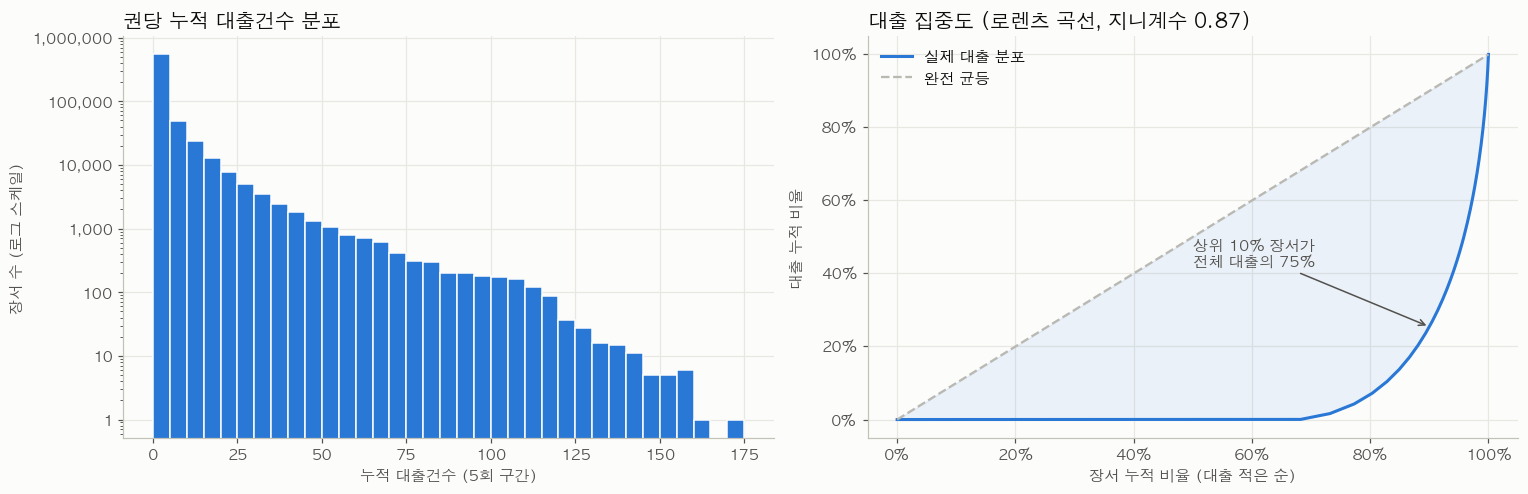

지니계수: 0.865  |  상위 10% 장서의 대출 점유율: 74.6%  |  상위 20%: 93.2%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (1) 대출건수 분포 (로그 스케일)
ax = axes[0]
bins = np.arange(0, df['대출건수'].max() + 6, 5)
ax.hist(df['대출건수'], bins=bins, color=BLUE, edgecolor='#fcfcfb', linewidth=1)
ax.set_yscale('log')
ax.set_title('권당 누적 대출건수 분포')
ax.set_xlabel('누적 대출건수 (5회 구간)')
ax.set_ylabel('장서 수 (로그 스케일)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))

# (2) 로렌츠 곡선 + 지니계수
ax = axes[1]
s = np.sort(df['대출건수'].values)
cum = np.cumsum(s) / s.sum()
x = np.arange(1, len(s) + 1) / len(s)
_trap = getattr(np, 'trapezoid', None) or np.trapz
gini = 1 - 2 * _trap(cum, x)
ax.plot(x, cum, color=BLUE, lw=2, label='실제 대출 분포')
ax.plot([0, 1], [0, 1], color=GRAY, lw=1.5, ls='--', label='완전 균등')
ax.fill_between(x, cum, x, color=BLUE, alpha=0.08)
top10 = 1 - np.interp(0.9, x, cum)
top20 = 1 - np.interp(0.8, x, cum)
ax.annotate(f'상위 10% 장서가\n전체 대출의 {top10:.0%}', xy=(0.9, 1 - top10), xytext=(0.5, 0.42),
            arrowprops=dict(arrowstyle='->', color=INK2), color=INK2)
ax.set_title(f'대출 집중도 (로렌츠 곡선, 지니계수 {gini:.2f})')
ax.set_xlabel('장서 누적 비율 (대출 적은 순)')
ax.set_ylabel('대출 누적 비율')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

print(f'지니계수: {gini:.3f}  |  상위 10% 장서의 대출 점유율: {top10:.1%}  |  상위 20%: {top20:.1%}')

In [7]:
# 대출건수 구간별 장서 구성
bins = [-1, 0, 2, 5, 10, 20, 50, 1000]
labels = ['0회', '1~2회', '3~5회', '6~10회', '11~20회', '21~50회', '51회 이상']
band = pd.cut(df['대출건수'], bins=bins, labels=labels)
band_tbl = pd.DataFrame({
    '장서 수': band.value_counts().reindex(labels),
    '대출 합계': df.groupby(band, observed=False)['대출건수'].sum().reindex(labels),
})
band_tbl['장서 비중(%)'] = band_tbl['장서 수'] / n * 100
band_tbl['대출 비중(%)'] = band_tbl['대출 합계'] / total_loans * 100
band_tbl

,장서 수,대출 합계,장서 비중(%),대출 비중(%)
대출건수,,,,
0회,449624,0,68.15,0.00
1~2회,59649,86602,9.04,4.16
3~5회,50111,193803,7.59,9.32
6~10회,42403,326182,6.43,15.68
11~20회,32395,471059,4.91,22.65
21~50회,20357,620580,3.09,29.84
51회 이상,5252,381586,0.80,18.35


## 3. 주제분류(KDC)별 분석

`수요지수 = 대출 비중 ÷ 장서 비중`. 1보다 크면 장서 규모에 비해 많이 빌려지는(공급이 부족한) 분야,
1보다 작으면 장서에 비해 덜 빌려지는(공급 과잉) 분야입니다.

In [8]:
def summarize(g):
    t = g.agg(장서수=('대출건수', 'size'), 대출합계=('대출건수', 'sum'), 평균대출=('대출건수', 'mean'),
              월평균대출=('월평균대출', 'mean'), 미대출률=('미대출', 'mean'))
    t['장서비중(%)'] = t['장서수'] / t['장서수'].sum() * 100
    t['대출비중(%)'] = t['대출합계'] / t['대출합계'].sum() * 100
    t['수요지수'] = t['대출비중(%)'] / t['장서비중(%)']
    t['미대출률'] = t['미대출률'] * 100
    return t.rename(columns={'미대출률': '미대출률(%)'})

subj = summarize(df.groupby('주제')).sort_values('대출비중(%)', ascending=False)
subj

,장서수,대출합계,평균대출,월평균대출,미대출률(%),장서비중(%),대출비중(%),수요지수
주제,,,,,,,,
문학,192157,743196,3.87,0.08,68.34,29.12,35.73,1.23
미분류,84375,387575,4.59,0.14,43.30,12.79,18.64,1.46
사회과학,119098,237060,1.99,0.04,77.08,18.05,11.40,0.63
총류,46260,196810,4.25,0.06,60.97,7.01,9.46,1.35
기술과학,48659,114162,2.35,0.04,71.97,7.37,5.49,0.74
자연과학,24751,109249,4.41,0.08,67.20,3.75,5.25,1.40
역사,43144,94109,2.18,0.04,75.03,6.54,4.52,0.69
철학,37051,80386,2.17,0.05,73.56,5.62,3.87,0.69
언어,16674,47777,2.87,0.05,77.62,2.53,2.30,0.91


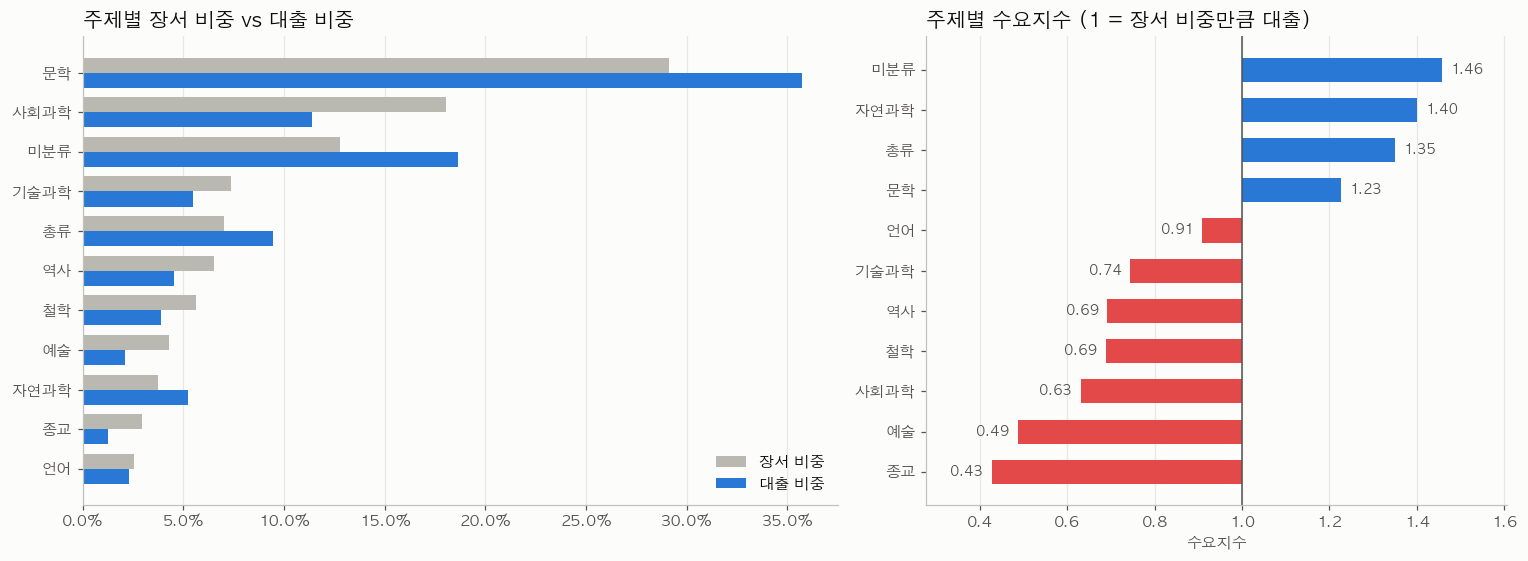

In [9]:
order = subj.sort_values('장서비중(%)').index
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.3, 1]})

ax = axes[0]
y = np.arange(len(order)); h = 0.38
ax.barh(y + h/2, subj.loc[order, '장서비중(%)'], height=h, color=GRAY, label='장서 비중')
ax.barh(y - h/2, subj.loc[order, '대출비중(%)'], height=h, color=BLUE, label='대출 비중')
ax.set_yticks(y, order)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('주제별 장서 비중 vs 대출 비중')
ax.legend(frameon=False, loc='lower right')
ax.grid(axis='y', visible=False)

ax = axes[1]
o2 = subj['수요지수'].sort_values()
colors = [BLUE if v >= 1 else RED for v in o2]
ax.barh(o2.index, o2 - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color=INK2, lw=1)
for i, v in enumerate(o2):
    ax.text(v + (0.02 if v >= 1 else -0.02), i, f'{v:.2f}', va='center',
            ha='left' if v >= 1 else 'right', color=INK2, fontsize=9)
ax.set_xlim(o2.min() - 0.15, o2.max() + 0.15)
ax.set_title('주제별 수요지수 (1 = 장서 비중만큼 대출)')
ax.set_xlabel('수요지수')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### 3-0. '미분류' 장서는 무엇인가?
주제분류번호가 비어 있는 장서가 장서 비중보다 훨씬 많이 대출되고 있어 따로 확인합니다.

In [10]:
u = df[df['주제'] == '미분류']
print('미분류 장서의 등록연도 분포:'); display(u['등록연도'].value_counts().sort_index().to_frame('권'))
print(f"미분류 중 부가기호(이용대상)도 없는 비율: {(u['이용대상'] == '미상').mean():.1%}")
print('미분류 장서 중 누적 대출 상위 10:')
u.sort_values('대출건수', ascending=False).head(10)[['도서명', '대표저자', '출판사', '발행년도', '등록일자', '대출건수']]

미분류 장서의 등록연도 분포:


,권
등록연도,
2020,15
2021,10491
2022,24306
2023,13787
2024,14064
2025,12171
2026,9541


미분류 중 부가기호(이용대상)도 없는 비율: 69.7%
미분류 장서 중 누적 대출 상위 10:


,도서명,대표저자,출판사,발행년도,등록일자,대출건수
312056,흔한남매 별난 방탈출 2,김언정,미래엔,"2,021.00",2022-03-03,123
312055,흔한남매 9,흔한남매,미래엔아이세움,"2,021.00",2022-03-03,123
301361,흔한남매의 흔한 호기심 5,안치현,미래엔아이세움,"2,022.00",2022-04-06,121
301370,흔한남매 오해요,유난희,미래엔아이세움,"2,022.00",2022-04-06,119
311096,흔한남매 과학 탐험대 1 : 우주,김덕영,김영사,"2,021.00",2022-03-03,115
312053,흔한남매 겨울밤 대소동,유난희,미래엔아이세움,"2,021.00",2022-03-03,115
312049,흔한남매 별난 방탈출 4,김언정,미래엔아이세움,"2,021.00",2022-03-03,115
310008,놓지 마 어휘 한자어 4,신태훈,주니어김영사,"2,022.00",2022-03-03,112
301385,흔한남매 과학 탐험대 4 : 물질,김덕영,주니어김영사,"2,022.00",2022-04-06,111
293277,흔한남매 불꽃 튀는 우리말 5,한은호,다산어린이,"2,022.00",2022-06-02,110


**해석**: 미분류 장서는 **2021년 이후 등록분에만** 존재하고, 대부분 부가기호도 비어 있습니다. 즉 특정 주제가 아니라
*분류 정보가 입력되지 않은 신규 장서*이며, 『흔한남매』, 『놓지 마 과학!』 같은 인기 아동 시리즈와 아동 전집이 많이 섞여 있어
대출이 높게 나옵니다. 이 때문에 주제별·이용대상별 비교에서 '미분류/미상' 수치는 별도로 해석해야 하며,
**목록 메타데이터(분류번호·부가기호) 보완**이 필요합니다. 또한 출판사 칸에 'STL / Faithworks Music' 같은 음반사명이
들어간 전집도 있어 일부 서지 정보 품질 문제가 확인됩니다.

### 3-1. 중분류(KDC 두 자리) 상세 — 수요가 높은/낮은 세부 분야

In [11]:
KDC2 = {
 '00':'총류','01':'도서학·서지학','02':'문헌정보학','03':'백과사전','04':'강연집·수필집','05':'일반연속간행물','07':'신문·언론','08':'일반전집·총서','09':'향토자료',
 '10':'철학','11':'형이상학','12':'인식론·인과론','13':'철학의 체계','14':'경학','15':'동양철학','16':'서양철학','17':'논리학','18':'심리학','19':'윤리학',
 '20':'종교','21':'비교종교','22':'불교','23':'기독교','24':'도교','25':'천도교','27':'힌두교','28':'이슬람교','29':'기타 종교',
 '30':'사회과학','31':'통계학','32':'경제학','33':'사회학·사회문제','34':'정치학','35':'행정학','36':'법학','37':'교육학','38':'풍속·민속학','39':'국방·군사학',
 '40':'자연과학','41':'수학','42':'물리학','43':'화학','44':'천문학','45':'지학','46':'광물학','47':'생명과학','48':'식물학','49':'동물학',
 '50':'기술과학','51':'의학','52':'농업','53':'공학·공업일반','54':'건축공학','55':'기계공학','56':'전기·전자공학','57':'화학공학','58':'제조업','59':'생활과학',
 '60':'예술','61':'건축술','62':'조각','63':'공예·장식미술','64':'서예','65':'회화·도화','66':'사진','67':'음악','68':'공연예술·매체예술','69':'오락·스포츠',
 '70':'언어','71':'한국어','72':'중국어','73':'일본어','74':'영어','75':'독일어','76':'프랑스어','77':'스페인어','78':'이탈리아어','79':'기타 언어',
 '80':'문학 일반(전집·총서 등)','81':'한국문학','82':'중국문학','83':'일본문학','84':'영미문학','85':'독일문학','86':'프랑스문학','87':'스페인문학','88':'이탈리아문학','89':'기타 문학',
 '90':'역사','91':'아시아사','92':'유럽사','93':'아프리카사','94':'북아메리카사','95':'남아메리카사','96':'오세아니아사','97':'양극지방사','98':'지리','99':'전기',
}
sub = summarize(df.dropna(subset=['KDC중분류']).groupby('KDC중분류'))
sub.insert(0, '분야', sub.index.map(KDC2))
sub = sub[sub['장서수'] >= 1000]   # 표본이 너무 작은 분야 제외
print('수요지수 상위 10개 중분류 (장서 1,000권 이상)')
display(sub.sort_values('수요지수', ascending=False).head(10)[['분야', '장서수', '평균대출', '미대출률(%)', '장서비중(%)', '대출비중(%)', '수요지수']])
print('수요지수 하위 10개 중분류 (장서 1,000권 이상)')
display(sub.sort_values('수요지수').head(10)[['분야', '장서수', '평균대출', '미대출률(%)', '장서비중(%)', '대출비중(%)', '수요지수']])

수요지수 상위 10개 중분류 (장서 1,000권 이상)


,분야,장서수,평균대출,미대출률(%),장서비중(%),대출비중(%),수요지수
KDC중분류,,,,,,,
80,문학 일반(전집·총서 등),19260,7.15,48.99,3.50,8.94,2.56
40,자연과학,7504,6.40,67.52,1.36,3.12,2.29
41,수학,4251,5.73,65.26,0.77,1.58,2.05
83,일본문학,14141,5.64,63.19,2.57,5.18,2.02
21,비교종교,1915,4.45,78.17,0.35,0.55,1.59
49,동물학,2545,4.41,63.97,0.46,0.73,1.58
50,기술과학,1221,4.20,85.01,0.22,0.33,1.50
71,한국어,4447,4.08,78.21,0.81,1.18,1.46
55,기계공학,2028,3.94,69.58,0.37,0.52,1.41


수요지수 하위 10개 중분류 (장서 1,000권 이상)


,분야,장서수,평균대출,미대출률(%),장서비중(%),대출비중(%),수요지수
KDC중분류,,,,,,,
61,건축술,1046,0.11,97.90,0.19,0.01,0.04
07,신문·언론,1499,0.39,87.86,0.27,0.04,0.14
35,행정학,2978,0.48,91.40,0.54,0.09,0.17
70,언어,1209,0.63,84.95,0.22,0.05,0.22
68,공연예술·매체예술,4743,0.65,86.74,0.86,0.20,0.23
34,정치학,10586,0.75,82.16,1.92,0.51,0.27
30,사회과학,7097,0.84,86.84,1.29,0.39,0.30
66,사진,1524,0.88,81.17,0.28,0.09,0.32
23,기독교,10901,0.91,78.16,1.98,0.65,0.33


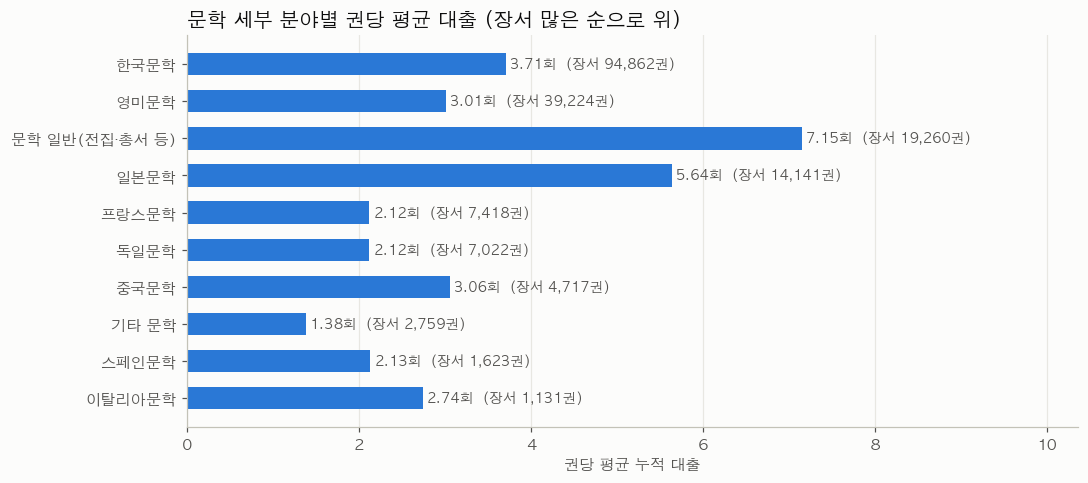

In [12]:
# 문학(8xx) 국가별 비교
lit = sub[sub.index.str.startswith('8')].sort_values('장서수', ascending=True)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(lit['분야'], lit['평균대출'], color=BLUE, height=0.6)
for i, (v, c) in enumerate(zip(lit['평균대출'], lit['장서수'])):
    ax.text(v + 0.05, i, f'{v:.2f}회  (장서 {c:,}권)', va='center', color=INK2, fontsize=9)
ax.set_title('문학 세부 분야별 권당 평균 대출 (장서 많은 순으로 위)')
ax.set_xlabel('권당 평균 누적 대출')
ax.set_xlim(0, lit['평균대출'].max() * 1.45)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

## 4. 이용대상(부가기호)별 분석

In [13]:
reader = summarize(df.groupby('이용대상')).sort_values('장서수', ascending=False)
reader

,장서수,대출합계,평균대출,월평균대출,미대출률(%),장서비중(%),대출비중(%),수요지수
이용대상,,,,,,,,
교양,233186,524749,2.25,0.04,73.46,35.34,25.23,0.71
미상,222389,875918,3.94,0.09,58.77,33.71,42.12,1.25
전문,71730,57813,0.81,0.01,83.78,10.87,2.78,0.26
아동,69612,455081,6.54,0.14,60.95,10.55,21.88,2.07
실용,41515,109461,2.64,0.04,74.29,6.29,5.26,0.84
청소년,11725,28742,2.45,0.05,60.35,1.78,1.38,0.78
학습참고(중고),5322,14163,2.66,0.05,64.75,0.81,0.68,0.84
학습참고(초등),3429,13266,3.87,0.07,83.96,0.52,0.64,1.23
여성,883,619,0.70,0.01,96.15,0.13,0.03,0.22


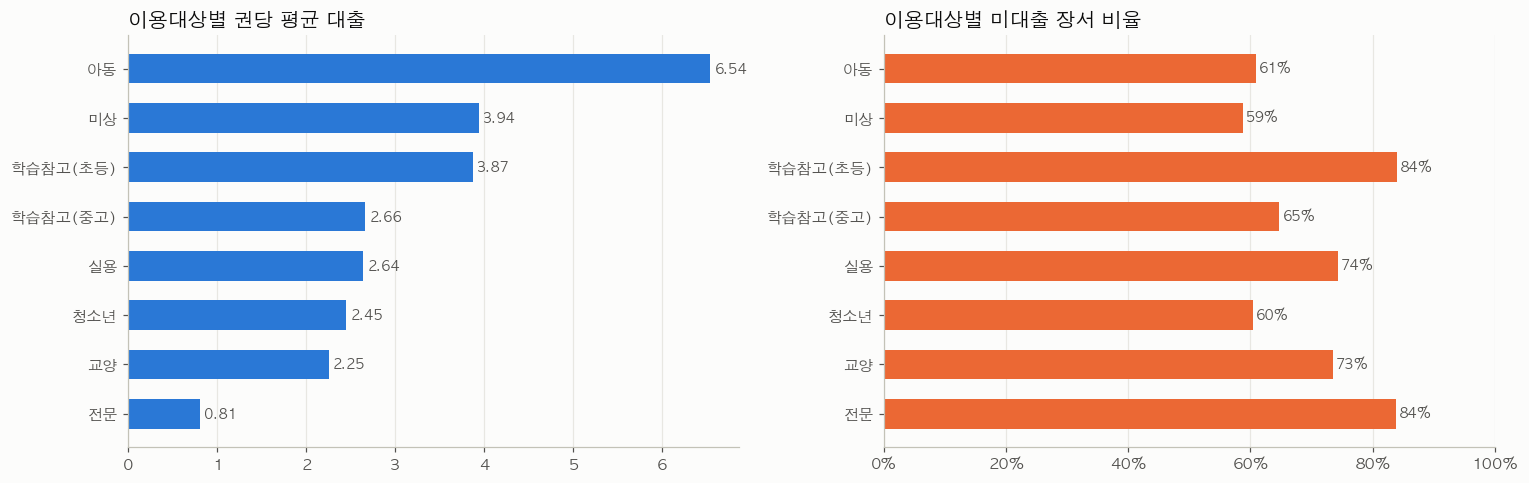

In [14]:
r = reader[reader['장서수'] >= 1000].sort_values('평균대출')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ax.barh(r.index, r['평균대출'], color=BLUE, height=0.6)
for i, v in enumerate(r['평균대출']):
    ax.text(v + 0.05, i, f'{v:.2f}', va='center', color=INK2, fontsize=9)
ax.set_title('이용대상별 권당 평균 대출')
ax.grid(axis='y', visible=False)
ax = axes[1]
ax.barh(r.index, r['미대출률(%)'], color=ORANGE, height=0.6)
for i, v in enumerate(r['미대출률(%)']):
    ax.text(v + 0.5, i, f'{v:.0f}%', va='center', color=INK2, fontsize=9)
ax.set_title('이용대상별 미대출 장서 비율')
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

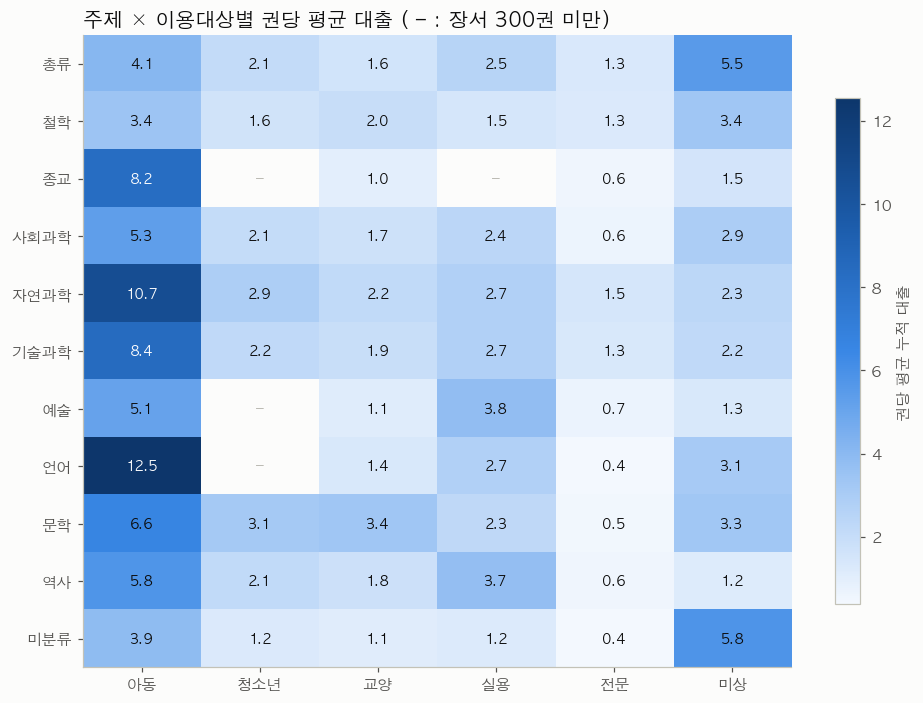

In [15]:
# 주제 × 이용대상 : 권당 평균 대출 히트맵 (해당 칸 장서 300권 이상만 표시)
cnt = pd.crosstab(df['주제'], df['이용대상'])
avg = df.pivot_table(index='주제', columns='이용대상', values='대출건수', aggfunc='mean')
cols = [c for c in ['아동', '청소년', '교양', '실용', '전문', '미상'] if c in avg.columns]
rows = [k for k in list(KDC.values()) + ['미분류'] if k in avg.index]
avg = avg.loc[rows, cols].where(cnt.loc[rows, cols] >= 300)

fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(avg.values, cmap=SEQ, aspect='auto')
ax.set_xticks(range(len(cols)), cols); ax.set_yticks(range(len(rows)), rows)
ax.grid(False)
vmax = np.nanmax(avg.values)
for i in range(len(rows)):
    for j in range(len(cols)):
        v = avg.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=9,
                    color='white' if v > vmax * 0.55 else '#0b0b0b')
        else:
            ax.text(j, i, '–', ha='center', va='center', color=GRAY)
ax.set_title('주제 × 이용대상별 권당 평균 대출 ( – : 장서 300권 미만)')
plt.colorbar(im, ax=ax, shrink=0.8, label='권당 평균 누적 대출')
plt.tight_layout(); plt.show()

## 5. 등록 시기(코호트) 분석

부산도서관은 2020년 11월 개관했습니다. 개관 전 대량으로 확보한 초기 장서와 이후 매년 추가된 신규 장서의 이용 양상을 비교합니다.

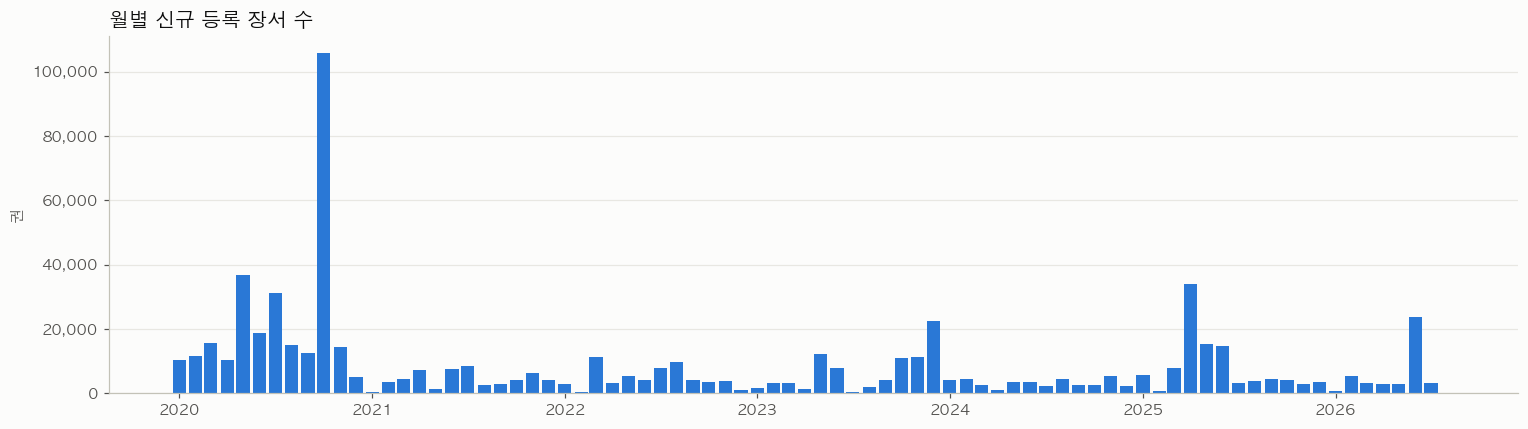

,장서수,평균대출,월평균대출,미대출률(%),평균보유개월
등록연도,,,,,
2020,287391,3.48,0.05,67.82,73.92
2021,53429,5.45,0.09,57.61,62.48
2022,56875,4.89,0.10,54.63,51.26
2023,80725,2.81,0.07,72.73,36.95
2024,38788,4.43,0.16,41.32,27.07
2025,100495,0.99,0.07,79.71,16.14
2026,42088,0.30,0.04,90.30,4.31


In [16]:
monthly = df.set_index('등록일자').resample('MS').size()
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(monthly.index, monthly.values, width=25, color=BLUE)
ax.set_title('월별 신규 등록 장서 수')
ax.set_ylabel('권')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

coh = df.groupby('등록연도').agg(장서수=('대출건수', 'size'), 평균대출=('대출건수', 'mean'),
                                 월평균대출=('월평균대출', 'mean'), 미대출률=('미대출', 'mean'),
                                 평균보유개월=('보유개월', 'mean'))
coh['미대출률'] *= 100
coh.rename(columns={'미대출률': '미대출률(%)'})

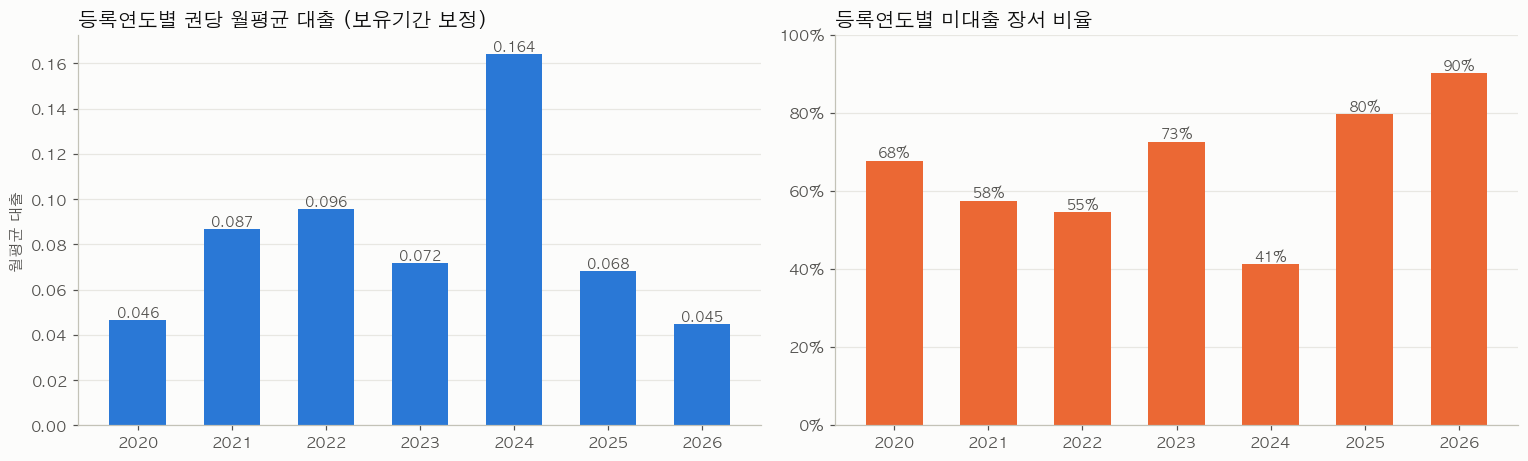

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
ax.bar(coh.index.astype(str), coh['월평균대출'], color=BLUE, width=0.6)
for i, v in enumerate(coh['월평균대출']):
    ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', color=INK2, fontsize=9)
ax.set_title('등록연도별 권당 월평균 대출 (보유기간 보정)')
ax.set_ylabel('월평균 대출')
ax.grid(axis='x', visible=False)

ax = axes[1]
ax.bar(coh.index.astype(str), coh['미대출률'], color=ORANGE, width=0.6)
for i, v in enumerate(coh['미대출률']):
    ax.text(i, v, f'{v:.0f}%', ha='center', va='bottom', color=INK2, fontsize=9)
ax.set_title('등록연도별 미대출 장서 비율')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

In [18]:
# 등록연도 × 주제 : 장서 구성 변화 (비중, %)
mix = pd.crosstab(df['등록연도'], df['주제'], normalize='index') * 100
mix = mix[[c for c in subj.index if c in mix.columns]]
mix.round(1)

주제,문학,미분류,사회과학,총류,기술과학,자연과학,역사,철학,언어,예술,종교
등록연도,,,,,,,,,,,
2020,32.40,0.00,19.20,12.40,7.60,4.20,6.70,6.50,3.20,4.70,3.00
2021,30.60,19.60,14.70,3.40,7.10,4.40,7.50,4.30,1.40,4.80,2.10
2022,22.90,42.70,12.60,1.50,5.80,1.60,6.10,2.60,1.30,1.60,1.30
2023,24.10,17.10,20.90,4.20,8.60,2.90,7.10,4.60,4.20,3.50,2.80
2024,25.50,36.30,12.60,2.80,4.60,2.80,4.40,5.30,1.30,2.40,1.90
2025,27.60,12.10,20.70,2.60,8.60,3.80,5.40,7.80,1.30,5.90,4.30
2026,29.90,22.70,15.20,2.00,5.60,5.20,8.10,2.40,1.60,3.70,3.50


## 6. 출간 연도 분석

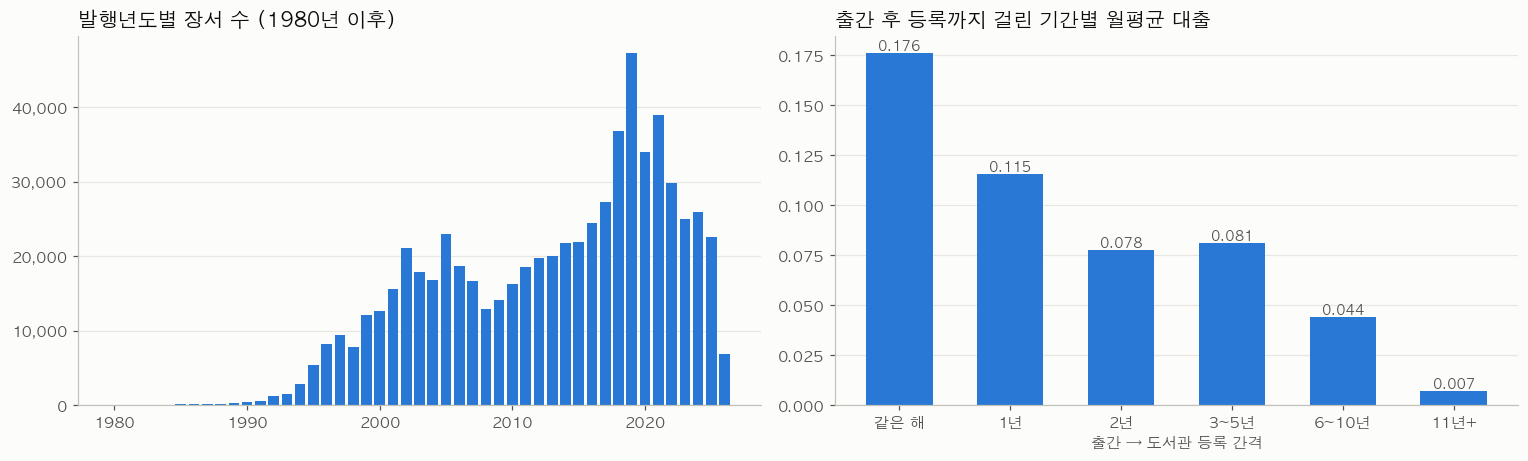

          장서수  월평균대출  미대출률
신간성                       
같은 해   117054   0.18  0.29
1년      81444   0.12  0.48
2년      43416   0.08  0.54
3~5년    63312   0.08  0.51
6~10년   70907   0.04  0.72
11년+   245100   0.01  0.95


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
py = df['발행년도'].dropna().astype(int)
py = py[py >= 1980].value_counts().sort_index()
ax.bar(py.index, py.values, color=BLUE, width=0.8)
ax.set_title('발행년도별 장서 수 (1980년 이후)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(axis='x', visible=False)

# 출간 후 몇 년 만에 들어왔는지(신간성) vs 월평균 대출 — 6개월 이상 보유 도서만
ax = axes[1]
d = df[(df['보유개월'] >= 6) & df['출간후등록(년)'].between(0, 30)].copy()
d['신간성'] = pd.cut(d['출간후등록(년)'], [-1, 0, 1, 2, 5, 10, 30],
                   labels=['같은 해', '1년', '2년', '3~5년', '6~10년', '11년+'])
fr = d.groupby('신간성', observed=True)['월평균대출'].mean()
ax.bar(fr.index.astype(str), fr.values, color=BLUE, width=0.6)
for i, v in enumerate(fr.values):
    ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', color=INK2, fontsize=9)
ax.set_title('출간 후 등록까지 걸린 기간별 월평균 대출')
ax.set_xlabel('출간 → 도서관 등록 간격')
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(d.groupby('신간성', observed=True).agg(장서수=('대출건수', 'size'), 월평균대출=('월평균대출', 'mean'),
                                           미대출률=('미대출', 'mean')))

## 7. 인기 도서·저자·출판사

In [20]:
# 같은 책(ISBN+도서명+권) 기준 인기 도서 — 복본 대출을 합산
book = (df.groupby('도서키')
          .agg(도서명=('도서명', 'first'), 저자=('대표저자', 'first'), 출판사=('출판사', 'first'),
               주제=('주제', 'first'), 이용대상=('이용대상', 'first'), 보유권수=('도서권수', 'sum'),
               대출합계=('대출건수', 'sum'))
          .sort_values('대출합계', ascending=False))
book['권당대출'] = book['대출합계'] / book['보유권수']
print('▶ 누적 대출 상위 20권 (같은 책 기준, 복본 합산)')
book.head(20).reset_index(drop=True)

▶ 누적 대출 상위 20권 (같은 책 기준, 복본 합산)


,도서명,저자,출판사,주제,이용대상,보유권수,대출합계,권당대출
0,물고기는 존재하지 않는다,룰루 밀러,곰출판,자연과학,미상,7,448,64.00
1,알사탕,백희나 글.,책읽는곰,미분류,미상,7,439,62.71
2,긴긴밤,루리,문학동네,미분류,미상,8,439,54.88
3,작별하지 않는다,한강,문학동네,미분류,교양,13,427,32.85
4,달러구트 꿈 백화점,이미예,팩토리나인,미분류,미상,10,410,41.00
5,바깥은 여름,김애란,문학동네,문학,교양,6,409,68.17
6,천 개의 파랑,천선란,허블,미분류,미상,6,358,59.67
7,이기적 유전자,리처드 도킨스,을유문화사,자연과학,미상,7,356,50.86
8,만복이네 떡집,김리리,비룡소,미분류,미상,4,333,83.25
9,흔한남매,흔한남매,미래엔,미분류,아동,3,329,109.67


In [21]:
# 시리즈 단위 (제목 정규화 후 묶음) 인기
series = (df.groupby('제목정규화')
            .agg(보유권수=('도서권수', 'sum'), 종수=('도서키', 'nunique'), 대출합계=('대출건수', 'sum'),
                 대표저자=('대표저자', lambda s: s.mode().iat[0] if s.notna().any() else ''))
            .sort_values('대출합계', ascending=False))
series['권당대출'] = series['대출합계'] / series['보유권수']
print('▶ 시리즈(제목 정규화) 단위 누적 대출 상위 15')
display(series.head(15))

# 성인 대상(교양·실용·전문) 도서 인기 상위 15 — 아동서 쏠림을 걷어내고 보기
print('▶ 성인 대상(부가기호 교양·실용·전문) 누적 대출 상위 15')
display(book[book['이용대상'].isin(['교양', '실용', '전문'])].head(15).reset_index(drop=True))

# 문학(KDC 8) 상위 15
print('▶ 문학 분야 누적 대출 상위 15')
display(book[book['주제'] == '문학'].head(15).reset_index(drop=True))

▶ 시리즈(제목 정규화) 단위 누적 대출 상위 15


,보유권수,종수,대출합계,대표저자,권당대출
제목정규화,,,,,
수학도둑,170,168,8848,송도수,52.05
마법천자문,114,101,7327,유대영,64.27
내일은 실험왕,53,52,4852,곰돌이 co.,91.55
그리스 로마 신화,256,163,4717,토마스 불핀치,18.43
흔한남매,67,39,4397,흔한남매,65.63
삼국지,313,267,3355,나관중,10.72
내일은 발명왕,46,43,3218,곰돌이 co.,69.96
한국사 대모험,73,42,3215,설민석,44.04
이상한 과자 가게 전천당,60,36,2947,히로시마 레이코,49.12


▶ 성인 대상(부가기호 교양·실용·전문) 누적 대출 상위 15


,도서명,저자,출판사,주제,이용대상,보유권수,대출합계,권당대출
0,작별하지 않는다,한강,문학동네,미분류,교양,13,427,32.85
1,바깥은 여름,김애란,문학동네,문학,교양,6,409,68.17
2,채식주의자,한강,창비,문학,교양,5,292,58.40
3,"오늘 밤, 세계에서 이 사랑이 사라진다 해도",이치조 미사키,모모,문학,교양,3,271,90.33
4,미드나잇 라이브러리,매트 헤이그,인플루엔셜,문학,교양,4,257,64.25
5,정의란 무엇인가,마이클 샌델,미래엔,사회과학,교양,4,255,63.75
6,지구에서 한아뿐,정세랑,난다,문학,교양,3,231,77.00
7,소년이 온다,한강,창비,미분류,교양,7,226,32.29
8,(가가형사 시리즈) 악의,히가시노 게이고,현대문학,문학,교양,2,224,112.00
9,곰탕.,김영탁,Arte(아르테),문학,교양,2,223,111.50


▶ 문학 분야 누적 대출 상위 15


,도서명,저자,출판사,주제,이용대상,보유권수,대출합계,권당대출
0,바깥은 여름,김애란,문학동네,문학,교양,6,409,68.17
1,불편한 편의점,김호연,나무옆의자,문학,미상,4,322,80.50
2,꽝 없는 뽑기 기계,곽유진,비룡소,문학,미상,4,312,78.00
3,아이스크림이 꽁꽁,구도 노리코,책읽는곰,문학,아동,4,306,76.50
4,채식주의자,한강,창비,문학,교양,5,292,58.40
5,이상한 과자 가게 전천당.,히로시마 레이코,길벗스쿨,문학,아동,4,291,72.75
6,바다가 들리는 편의점,마치다 소노코,바이포엠 스튜디오,문학,미상,6,280,46.67
7,흔한남매.,흔한남매,미래엔아이세움,문학,아동,2,277,138.50
8,"오늘 밤, 세계에서 이 사랑이 사라진다 해도",이치조 미사키,모모,문학,교양,3,271,90.33
9,흔한남매.,흔한남매,미래엔아이세움,문학,아동,3,264,88.00


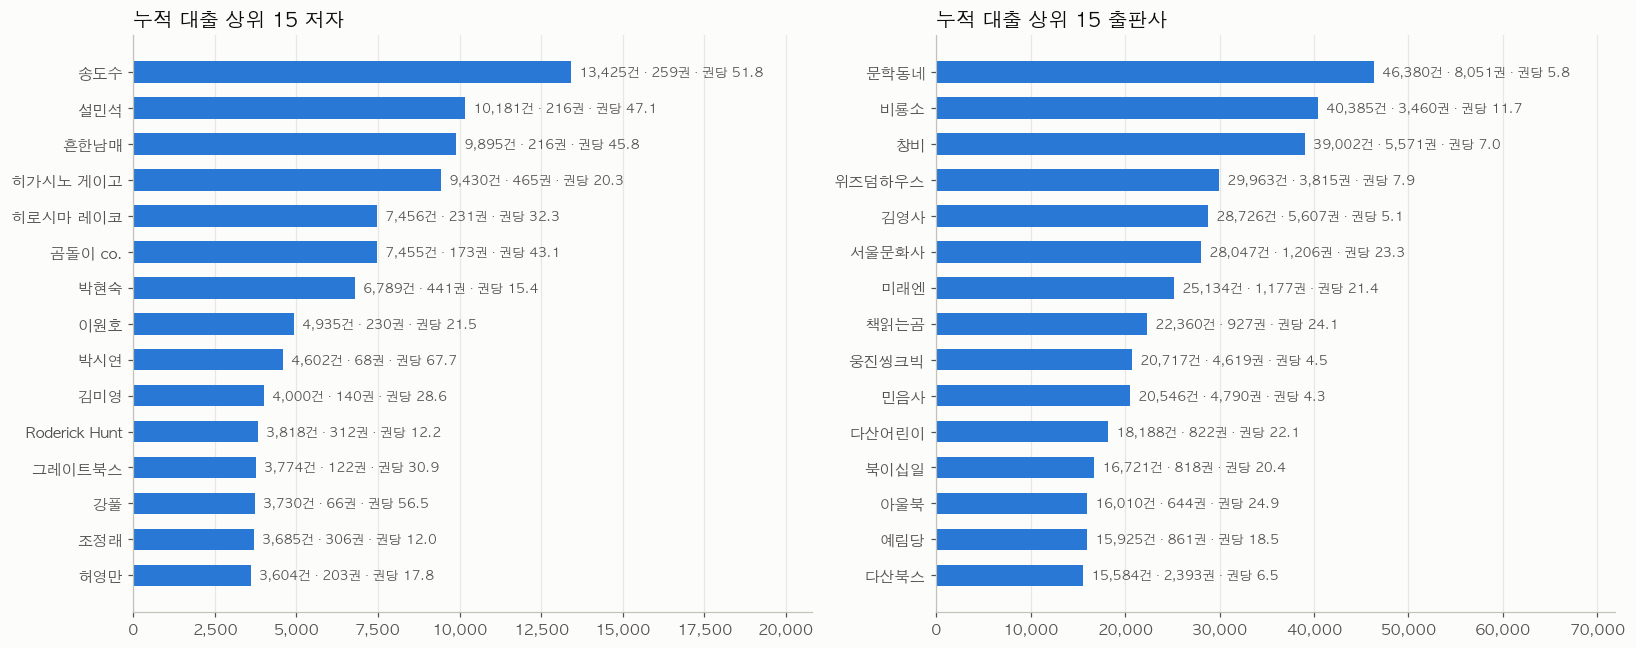

In [22]:
auth = (df.dropna(subset=['대표저자']).groupby('대표저자')
          .agg(장서수=('대출건수', 'size'), 종수=('도서키', 'nunique'), 대출합계=('대출건수', 'sum'),
               미대출률=('미대출', 'mean')))
auth['권당대출'] = auth['대출합계'] / auth['장서수']
top_auth = auth.sort_values('대출합계', ascending=False).head(15)

pub = (df.dropna(subset=['출판사']).groupby('출판사')
         .agg(장서수=('대출건수', 'size'), 대출합계=('대출건수', 'sum'), 미대출률=('미대출', 'mean')))
pub['권당대출'] = pub['대출합계'] / pub['장서수']
top_pub = pub.sort_values('대출합계', ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, t, title in [(axes[0], top_auth, '누적 대출 상위 15 저자'), (axes[1], top_pub, '누적 대출 상위 15 출판사')]:
    t = t.iloc[::-1]
    ax.barh(t.index, t['대출합계'], color=BLUE, height=0.6)
    for i, (v, c, p) in enumerate(zip(t['대출합계'], t['장서수'], t['권당대출'])):
        ax.text(v, i, f'  {v:,}건 · {c:,}권 · 권당 {p:.1f}', va='center', color=INK2, fontsize=8.5)
    ax.set_xlim(0, t['대출합계'].max() * 1.55)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [23]:
# 효율 관점: 장서 300권 이상 출판사 중 권당 대출 상·하위
big = pub[pub['장서수'] >= 300].copy()
big['미대출률'] *= 100
print('▶ 권당 대출 상위 10 출판사 (장서 300권 이상)')
display(big.sort_values('권당대출', ascending=False).head(10))
print('▶ 권당 대출 하위 10 출판사 (장서 300권 이상)')
display(big.sort_values('권당대출').head(10))

▶ 권당 대출 상위 10 출판사 (장서 300권 이상)


,장서수,대출합계,미대출률,권당대출
출판사,,,,
미래엔아이세움,396,15433,7.83,38.97
아울북,644,16010,12.42,24.86
책읽는곰,927,22360,20.39,24.12
서울문화사,1206,28047,47.76,23.26
다산어린이,822,18188,11.31,22.13
미래엔,1177,25134,49.11,21.35
북이십일,818,16721,47.68,20.44
주니어김영사,699,13881,15.02,19.86
예림당,861,15925,50.87,18.50


▶ 권당 대출 하위 10 출판사 (장서 300권 이상)


,장서수,대출합계,미대출률,권당대출
출판사,,,,
내츄럴,2286,0,100.00,0.00
민족문화추진회,341,0,100.00,0.00
산업연구원,580,0,100.00,0.00
한국행정연구원,303,0,100.00,0.00
고려원,379,0,100.00,0.00
경기개발연구원,475,0,100.00,0.00
생각의 나무,501,2,99.60,0.00
학문사,356,2,99.44,0.01
두산동아,375,3,99.20,0.01


## 8. 복본 분석

같은 책(ISBN+도서명+권)을 여러 권 가진 경우, 복본이 늘수록 권당 대출이 어떻게 달라지는지 봅니다. (인기 있는 책에 복본을 사므로 인과가 아닌 **배치 효율**의 관점으로 해석)

,도서종수,종당대출,권당대출,전부미대출비율
복본구간,,,,
1권,414077,3.35,3.35,64.56
2권,79989,6.23,3.11,56.69
3권,12749,9.96,3.32,47.60
4~5권,6595,7.87,1.88,76.97
6권+,2687,6.26,0.87,78.71


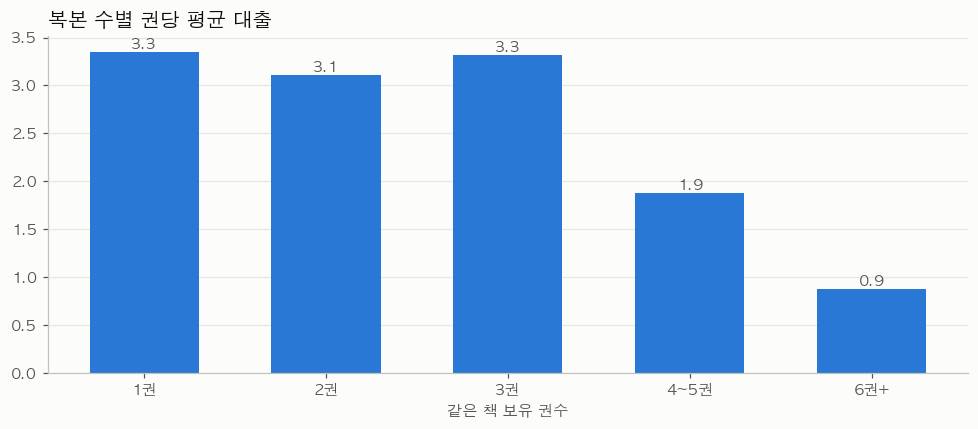

In [24]:
book['복본구간'] = pd.cut(book['보유권수'], [0, 1, 2, 3, 5, 1000], labels=['1권', '2권', '3권', '4~5권', '6권+'])
cp = book.groupby('복본구간', observed=True).agg(도서종수=('대출합계', 'size'), 종당대출=('대출합계', 'mean'),
                                                권당대출=('권당대출', 'mean'),
                                                전부미대출비율=('대출합계', lambda s: (s == 0).mean() * 100))
display(cp)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(cp.index.astype(str), cp['권당대출'], color=BLUE, width=0.6)
for i, v in enumerate(cp['권당대출']):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom', color=INK2)
ax.set_title('복본 수별 권당 평균 대출')
ax.set_xlabel('같은 책 보유 권수')
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

In [25]:
# 4권 이상 복본인데 한 번도 대출되지 않은 책들 — 어떤 책들인가?
bulk = book[(book['보유권수'] >= 4) & (book['대출합계'] == 0)]
first_reg = df.groupby('도서키')['등록일자'].min()
print(f'4권 이상 복본 & 대출 0회: {len(bulk):,}종, {bulk["보유권수"].sum():,}권')
print('최초 등록연도 분포:'); display(first_reg.loc[bulk.index].dt.year.value_counts().sort_index().to_frame('종수'))
bulk.sort_values('보유권수', ascending=False).head(10)[['도서명', '출판사', '주제', '보유권수', '대출합계']].reset_index(drop=True)

4권 이상 복본 & 대출 0회: 7,191종, 39,621권
최초 등록연도 분포:


,종수
등록일자,
2020,6863
2021,74
2022,87
2023,42
2024,40
2025,77
2026,8


,도서명,출판사,주제,보유권수,대출합계
0,반짝반짝 추억 전당포 : 요시노 마리코 장편소설,콘텐츠그룹 포레스트,미분류,37,0
1,걸어서 코리아 : 201일간의 대한민국 방방곡곡 걷기여행,미다스북스,미분류,37,0
2,산골 노승의 푸른 목소리 : 자유롭고 당당하게 오늘의 주인공으로 살아가는 삶,불광출판사,미분류,37,0
3,(기초의 기초부터 배우는) 나의 첫 인형옷 교과서,라의눈,미분류,37,0
4,요즘 팀장의 오답 노트 : 팀 성과를 좌우하는 여럿이 일 잘하는 법,웅진씽크빅,미분류,37,0
5,별빛이 우리에게 알려주는 것들 : 모두를 위한 쉽고 재미있는 우주 이야기,케렌시아,미분류,37,0
6,MBC의 흑역사 : 방송의 중립에는 좌우가 없다,인물과사상사,미분류,37,0
7,깨어있는 양육 : 아이가 보내는 신호를 제대로 읽고 소통하는 법,나무의마음,미분류,37,0
8,러브드 : 사랑받는 제품을 만드는 실리콘밸리 마케팅 전략,Jpub(제이펍),미분류,37,0
9,(사진으로 쉽게 알아보는)한국의 야생화 대백과 도감 : 우리산과 들에 숨쉬고 있는 보물,윤미디어,미분류,37,0


**해석**
- 복본 **2~3권**: 책 한 종의 대출은 2~3배로 늘면서도 권당 대출(3.1~3.3회)은 1권짜리와 비슷하게 유지됩니다 → 인기 도서에 대한 2~3권 복본은 **효율적**입니다.
- 복본 **4권 이상**: 권당 대출이 급락하고 77~79%는 한 권도 빌려지지 않았습니다. 이런 책의 95%(7,191종 중 6,863종)는 개관 초기인 **2020년에 일괄 등록**되었고,
  2025년에 같은 책을 37권씩 등록한 사례도 있습니다. 이들은 본관 대출용이 아니라 **작은도서관 순회·배분용 등 특수 목적으로 구입된 장서로 추정**됩니다.
  대출 데이터만 보면 대량 복본 구입의 효과는 낮으므로 용도를 확인해 볼 필요가 있습니다.

## 9. 미대출 장서 분석

보유한 지 **2년 이상** 지났는데도 한 번도 대출되지 않은 장서를 '장기 미대출'로 정의합니다.

2년 이상 보유 장서: 507,171권 → 그중 장기 미대출: 326,821권 (64.4%)

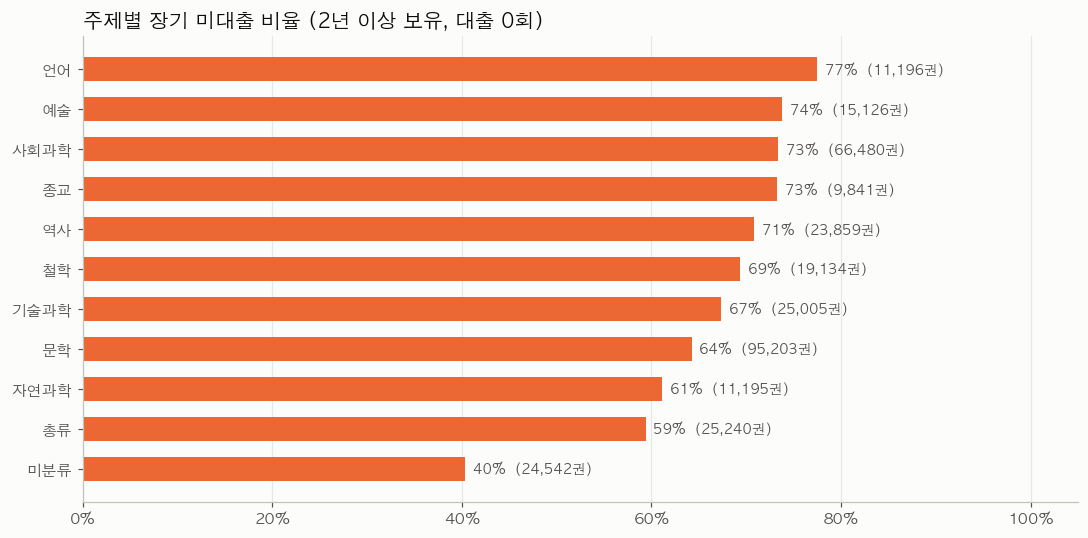

In [26]:
old = df[df['보유개월'] >= 24]
dead = old[old['미대출']]
print(f'2년 이상 보유 장서: {len(old):,}권 → 그중 장기 미대출: {len(dead):,}권 ({len(dead)/len(old):.1%})')

dd = pd.DataFrame({'장기미대출': dead.groupby('주제').size(), '2년이상보유': old.groupby('주제').size()})
dd['장기미대출률(%)'] = dd['장기미대출'] / dd['2년이상보유'] * 100
dd = dd.sort_values('장기미대출률(%)')

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(dd.index, dd['장기미대출률(%)'], color=ORANGE, height=0.6)
for i, (v, c) in enumerate(zip(dd['장기미대출률(%)'], dd['장기미대출'])):
    ax.text(v + 0.8, i, f'{v:.0f}%  ({c:,}권)', va='center', color=INK2, fontsize=9)
ax.set_xlim(0, 105)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('주제별 장기 미대출 비율 (2년 이상 보유, 대출 0회)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [27]:
# 장기 미대출 장서의 특징: 발행년도·이용대상 구성 비교 (전체 2년+ 보유 장서 대비)
cmp_age = pd.DataFrame({
    '장기미대출': pd.cut(dead['발행년도'], [0, 1999, 2009, 2014, 2019, 2026]).value_counts(normalize=True).sort_index() * 100,
    '대출된 장서': pd.cut(old.loc[~old['미대출'], '발행년도'], [0, 1999, 2009, 2014, 2019, 2026]).value_counts(normalize=True).sort_index() * 100,
})
cmp_age.index = ['~1999', '2000~09', '2010~14', '2015~19', '2020~']
print('▶ 발행년도 구성 비교 (%)'); display(cmp_age.round(1))

cmp_reader = pd.DataFrame({
    '장기미대출': dead['이용대상'].value_counts(normalize=True) * 100,
    '대출된 장서': old.loc[~old['미대출'], '이용대상'].value_counts(normalize=True) * 100,
}).fillna(0).sort_values('장기미대출', ascending=False)
print('▶ 이용대상 구성 비교 (%)'); display(cmp_reader.round(1))

▶ 발행년도 구성 비교 (%)


,장기미대출,대출된 장서
~1999,13.10,0.80
2000~09,35.30,5.10
2010~14,13.60,10.20
2015~19,24.10,34.80
2020~,13.90,49.20


▶ 이용대상 구성 비교 (%)


,장기미대출,대출된 장서
이용대상,,
교양,36.00,28.50
미상,35.10,45.90
전문,13.50,6.00
아동,6.40,11.00
실용,6.20,5.30
청소년,1.40,2.20
학습참고(중고),0.70,1.00
학습참고(초등),0.60,0.20
여성,0.20,0.00


## 10. 종합 인사이트 및 제언

### 핵심 발견

| # | 발견 | 근거 |
|---|---|---|
| 1 | **대출이 극소수 장서에 쏠려 있다** | 장서의 **68%는 한 번도 대출되지 않았고**, 상위 10% 장서가 전체 대출의 **75%**, 상위 20%가 **93%** 를 차지 (지니계수 0.87) |
| 2 | **아동 도서가 도서관 대출을 견인한다** | 아동 도서는 장서의 10.6%지만 대출의 21.9% (수요지수 2.07). 특히 아동용 언어(12.5회)·자연과학(10.7회) 책의 권당 대출이 가장 높음. 인기 시리즈 1~15위도 『수학도둑』, 『마법천자문』, 『내일은 실험왕』, 『흔한남매』 등 학습만화가 차지 |
| 3 | **전문서·사회과학·종교·예술은 공급 과잉** | 전문 도서는 장서 10.9% → 대출 2.8% (미대출 84%). 사회과학은 장서의 18%를 차지하지만 대출은 11%. 종교(0.43), 예술(0.49) 수요지수 최저. 중분류로는 건축술·행정학·정치학·신문언론·기독교가 최하위 |
| 4 | **문학, 특히 일본문학·한국 현대소설의 수요가 높다** | 문학은 장서 29% → 대출 36%. 일본문학 수요지수 2.02 (히가시노 게이고 누적 9,430건). 성인 인기 도서는 한강·김애란·김호연·정세랑·정해연 등 한국 현대소설 중심 |
| 5 | **'신간성'이 대출을 좌우한다** | 출간 당해에 들어온 책의 월평균 대출은 0.176회, 출간 11년 이상 지나 들어온 책은 0.007회로 **약 25배 차이**. 11년+ 책의 95%는 대출 0회 |
| 6 | **개관 초기 장서와 장기 미대출 문제** | 2020년 개관 전후로 28.7만 권(전체의 44%)이 한꺼번에 등록되었고 이 중 상당수가 오래된 책. 2년 이상 보유했는데 대출 0회인 장서가 **32.7만 권(64%)** 이며, 이 중 48%가 2009년 이전 출간 (대출된 장서는 6%) |
| 7 | **복본은 2~3권까지가 효율적** | 2~3권 복본은 권당 대출을 유지하며 종당 대출을 2~3배로 늘림. 4권 이상 대량 복본은 77~79%가 미대출 |
| 8 | **서지 데이터 품질 보완 필요** | 주제분류번호 13%, 부가기호 33% 결측(대부분 2021년 이후 등록분, 인기 아동서 다수 포함), 출판사 칸에 음반사명이 들어간 전집 등 오류 존재 |

### 제언

1. **수요 기반 장서 개발**: 수요지수가 높은 분야(아동 지식·학습 도서, 일본문학, 한국 현대소설, 수학·자연과학 교양서)의
   구입 비중을 늘리고, 수요지수가 낮은 분야(전문서, 행정·정치, 종교, 건축·공연예술)는 구입 기준을 엄격히 합니다.
2. **신간 중심 구입**: 출간 후 1년 이내 도서의 이용률이 압도적으로 높으므로, 신간을 빠르게 들여오는 구조(희망도서·신간 정기 구입)를 강화합니다.
3. **인기 도서 2~3권 복본, 대량 복본 지양**: 대출 상위권 도서는 2~3권으로 늘려 대기를 줄이고, 4권 이상 일괄 구입은 목적을 재검토합니다.
4. **장기 미대출 장서 관리**: 2년 이상 대출 0회 장서(특히 2009년 이전 출간분)는 ① 주제 전시·큐레이션으로 재노출하고,
   ② 그래도 이용되지 않으면 보존서고 이관 또는 제적을 검토해 개가 서가를 인기 분야에 재배분합니다.
5. **목록 데이터 정비**: 분류번호·부가기호 결측과 출판사 오류를 보완하면 이후 분석과 이용자 검색 품질이 함께 좋아집니다.

### 분석의 한계
- `대출건수`가 **누적값**이라 월별 대출 추이나 계절성은 알 수 없습니다(월평균 대출로 보유기간만 보정).
- 이용자 정보(연령·성별), 자료실 위치, 예약·대기 건수가 없어 수요의 원인까지는 확인할 수 없습니다.
- 같은 책이라도 판본·표기가 다르면(예: '곰탕' / '곰탕.') 다른 책으로 집계될 수 있습니다.
- 4권 이상 대량 복본의 용도(순회·배분용 등)는 데이터만으로 확정할 수 없는 추정입니다.